In [102]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [103]:
path = r"files\WMDI-files\employee_attrition.csv"
data = pd.read_csv(path)

### Data UnderstandinG

In [104]:
data.head()

,EmployeeID,Age,Gender,Department,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Attrition
0,1,38.0,Male,HR,0.000000,0.40,No,2.0,3,0.5,No
1,2,33.0,Male,HR,0.075385,0.25,No,2.0,2,0.3,No
2,3,40.0,Female,Sales,0.136375,0.70,No,1.0,2,0.5,No
3,4,47.0,Male,HR,0.174409,0.60,No,3.0,3,0.2,No
4,5,33.0,Female,IT,0.153290,0.20,No,NaN,3,0.1,Yes


In [105]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8400 entries, 0 to 8399
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   EmployeeID             8400 non-null   int64  
 1   Age                    7561 non-null   float64
 2   Gender                 8400 non-null   object 
 3   Department             8400 non-null   object 
 4   MonthlyIncome          7556 non-null   float64
 5   YearsAtCompany         8400 non-null   float64
 6   OverTime               8400 non-null   object 
 7   JobSatisfaction        7567 non-null   float64
 8   WorkLifeBalance        8400 non-null   int64  
 9   TrainingTimesLastYear  8400 non-null   float64
 10  Attrition              8400 non-null   object 
dtypes: float64(5), int64(2), object(4)
memory usage: 722.0+ KB


In [106]:
# Spot Outliers
data.describe()

,EmployeeID,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear
count,8400.000000,7561.000000,7556.000000,8400.000000,7567.000000,8400.000000,8400.000000
mean,3994.265952,34.657849,0.191155,0.296810,2.189771,2.543690,0.226202
std,2311.555446,7.633779,0.157068,0.204295,1.015183,0.982885,0.148470
min,1.000000,22.000000,0.000000,0.000000,1.000000,1.000000,0.000000
25%,1987.750000,29.000000,0.062035,0.150000,1.000000,2.000000,0.100000
50%,3990.500000,34.000000,0.167131,0.300000,2.000000,3.000000,0.200000
75%,6002.000000,40.000000,0.288324,0.450000,3.000000,3.000000,0.300000
max,8000.000000,60.000000,1.000000,1.000000,4.000000,4.000000,1.000000


### Remove Irrelevant Columns/Features/Variables

In [107]:
data.drop("EmployeeID", axis=1, inplace=True)

In [108]:
data.head()

,Age,Gender,Department,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Attrition
0,38.0,Male,HR,0.000000,0.40,No,2.0,3,0.5,No
1,33.0,Male,HR,0.075385,0.25,No,2.0,2,0.3,No
2,40.0,Female,Sales,0.136375,0.70,No,1.0,2,0.5,No
3,47.0,Male,HR,0.174409,0.60,No,3.0,3,0.2,No
4,33.0,Female,IT,0.153290,0.20,No,NaN,3,0.1,Yes


### Handle Missing values

In [109]:
data.isnull().sum() # confirm the missing values

Age                      839
Gender                     0
Department                 0
MonthlyIncome            844
YearsAtCompany             0
OverTime                   0
JobSatisfaction          833
WorkLifeBalance            0
TrainingTimesLastYear      0
Attrition                  0
dtype: int64

In [110]:
data.isnull().mean()*100 # percentage of missing values

Age                       9.988095
Gender                    0.000000
Department                0.000000
MonthlyIncome            10.047619
YearsAtCompany            0.000000
OverTime                  0.000000
JobSatisfaction           9.916667
WorkLifeBalance           0.000000
TrainingTimesLastYear     0.000000
Attrition                 0.000000
dtype: float64

#### Lets visualize the missing values for easy communications with HR/Stakeholders

In [111]:
import missingno as msno


<Axes: >

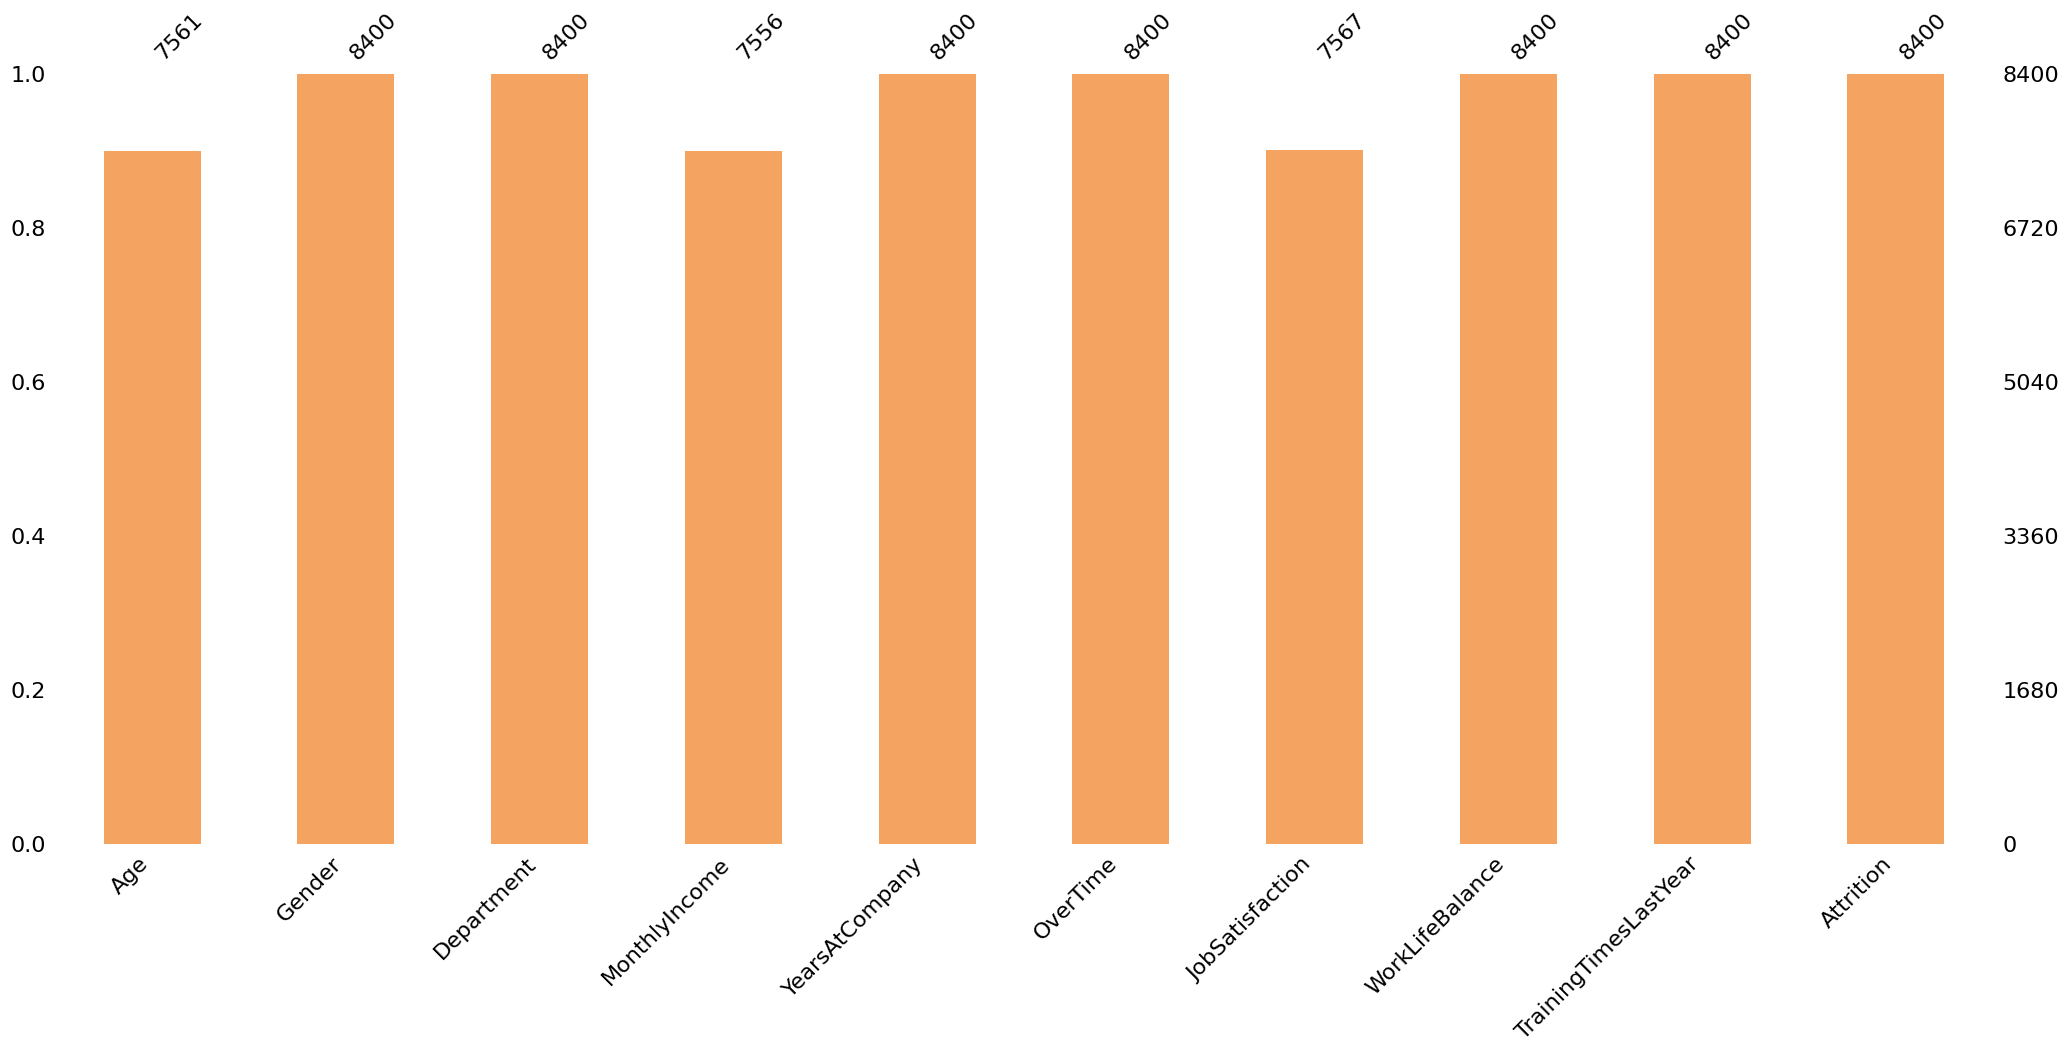

In [112]:
msno.bar(data, color='sandybrown')

<Axes: >

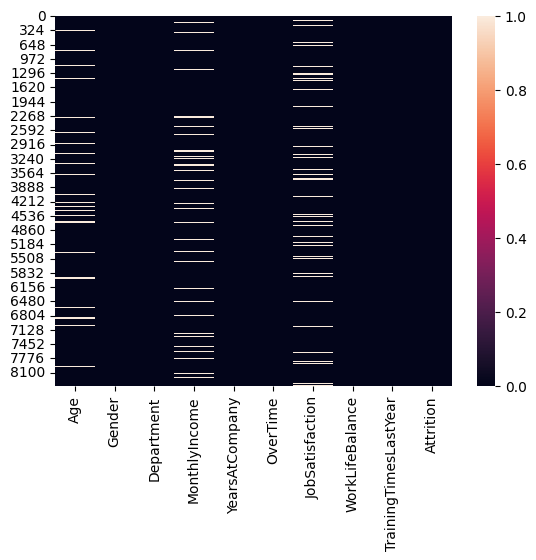

In [113]:
# Display columns with missing values
sns.heatmap(data.isnull())

#### Imputation Strategies
**Numerical Columns:**
- Use `mean`, or  `median` to impute.
- For features like `Age`, median is often more robust against outliers.

**Categorical Columns:**
- Impute with the mode or create a new category (e.g., "Unknown").

**Advanced Options:**
- Use K-Nearest Neighbors (KNN) Imputation or regression models for more accurate imputation.

In [114]:
# Impute missing numerical values with median
data['Age'] = data['Age'].fillna(data['Age'].median())
data['MonthlyIncome'] = data['MonthlyIncome'].fillna(data['MonthlyIncome'].median())

In [115]:
# Impute missing categorical values with mode
data['JobSatisfaction'] = data['JobSatisfaction'].fillna(data['JobSatisfaction'].mode()[0]) # Mode can appear multiple times, [0] picks the first one

In [116]:
data.isnull().sum()

Age                      0
Gender                   0
Department               0
MonthlyIncome            0
YearsAtCompany           0
OverTime                 0
JobSatisfaction          0
WorkLifeBalance          0
TrainingTimesLastYear    0
Attrition                0
dtype: int64

### Handling Duplicate Data
Detect Duplicates

In [117]:
# Check for duplicate rows
data.duplicated().sum()

408

### Remove Duplicates
- Duplicates can often be dropped unless there’s a need to retain them for specific analysis.

In [118]:
len(data)

8400

In [119]:
data = data.drop_duplicates().reset_index(drop=True)

In [120]:
len(data)

7992

### Handle Outliers
Check for outliers in numerical columns.<br>
Lets investigate the numerical columns for outliers by visualizing their distributions on histplot

In [121]:
numerical_columns = data.select_dtypes(include="number")

In [122]:
numerical_columns

,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear
0,38.0,0.000000,0.40,2.0,3,0.5
1,33.0,0.075385,0.25,2.0,2,0.3
2,40.0,0.136375,0.70,1.0,2,0.5
3,47.0,0.174409,0.60,3.0,3,0.2
4,33.0,0.153290,0.20,1.0,3,0.1
...,...,...,...,...,...,...
7987,52.0,0.334159,0.80,1.0,3,0.3
7988,37.0,0.000000,0.15,4.0,3,0.1
7989,28.0,0.109883,0.10,3.0,3,0.3
7990,34.0,0.092938,0.65,2.0,4,0.1


In [123]:
len(numerical_columns.columns)

6

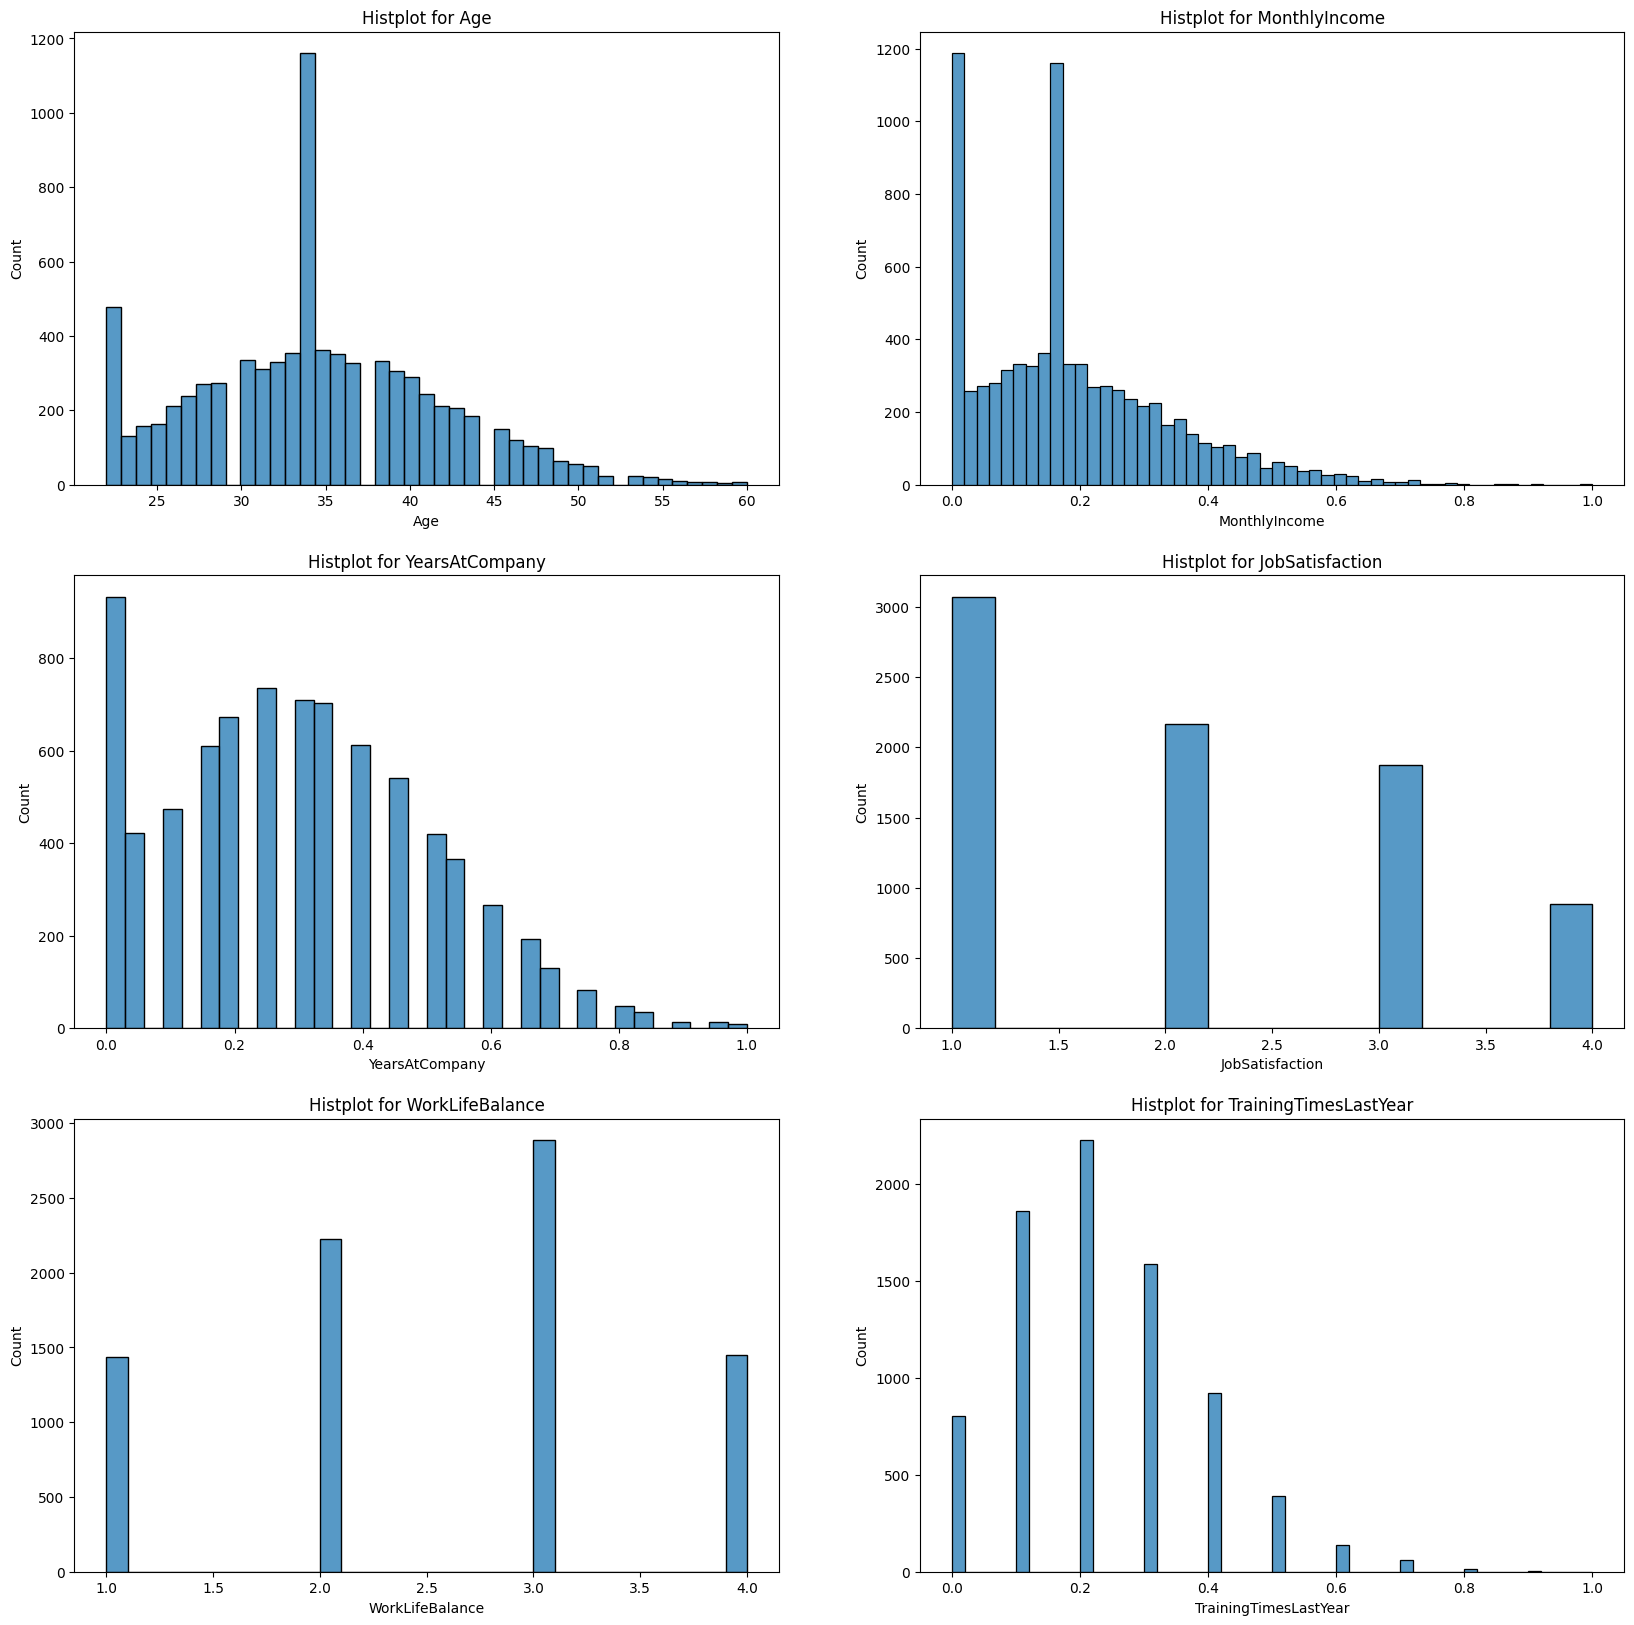

In [124]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(20, 20))
ax=ax.flatten()
for idx, col in enumerate(numerical_columns):
    sns.histplot(data[col], ax=ax[idx])
    ax[idx].set_title(f"Histplot for {col}")
plt.show()

NOTE: JobSatisfaction is a Category represented by Numerical values. Therefore, we cant consider it skewed or have outliers

#### We can use Boxplot to further confirm the outliers in numerical columns

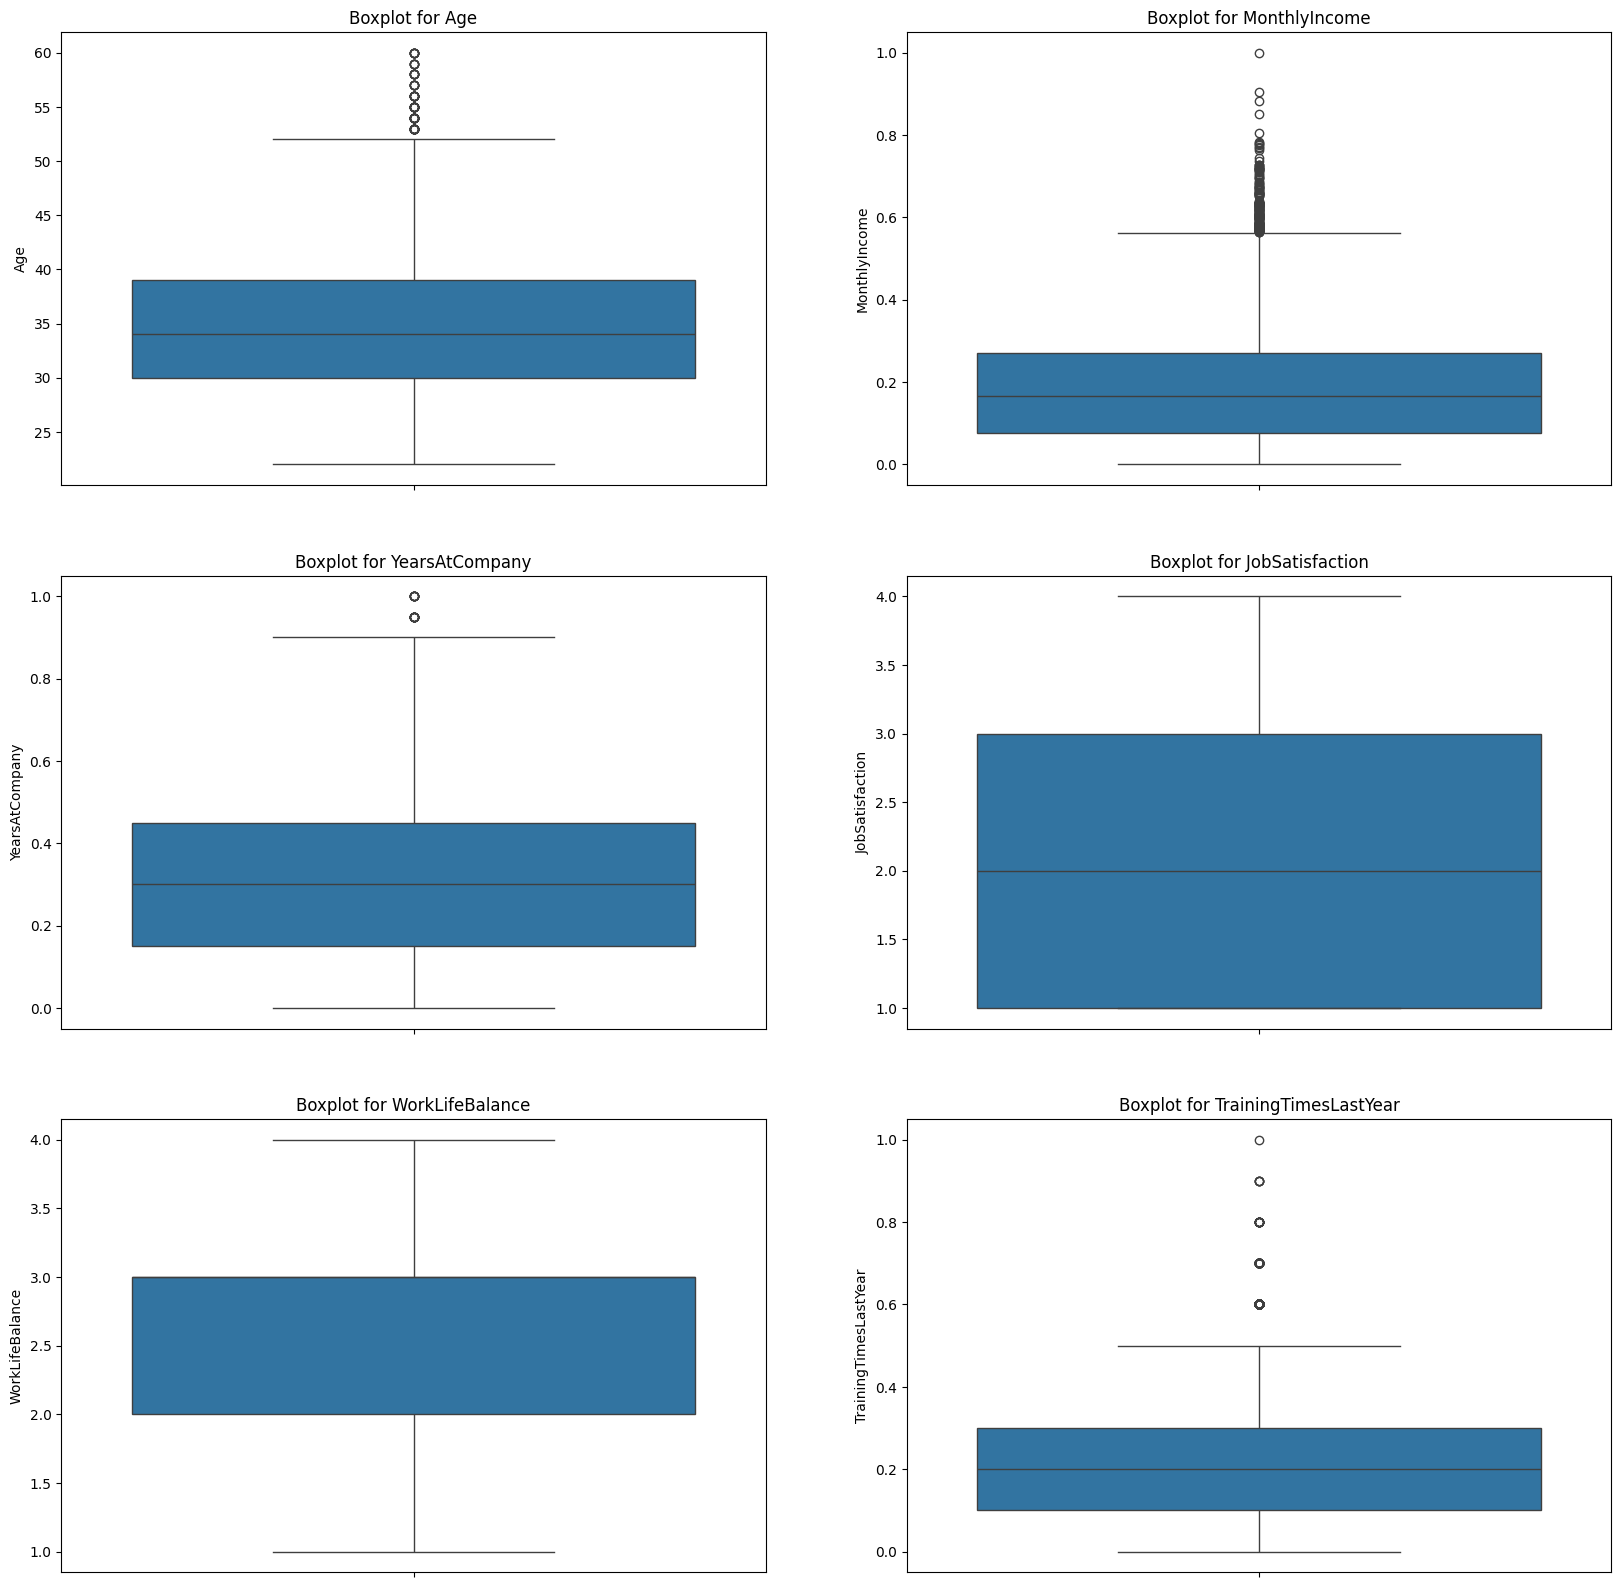

In [125]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(20, 20))
ax=ax.flatten()
for idx, col in enumerate(numerical_columns):
    sns.boxplot(data[col], ax=ax[idx])
    ax[idx].set_title(f"Boxplot for {col}")
plt.show()

NOTE: JobSatisfaction and WorlkLifeBalance arent pointing to outliers because they are Categorical

### Lets remove the outliers on affected columns using IQR

In [126]:
affected_column = ["Age", "MonthlyIncome", "YearsAtCompany", "TrainingTimesLastYear"]

In [127]:
# iqr = q3 - q1
q1 = data[affected_column].quantile(0.25)
q3 = data[affected_column].quantile(0.75)

In [128]:
iqr = q3 - q1
iqr

Age                      9.00000
MonthlyIncome            0.19467
YearsAtCompany           0.30000
TrainingTimesLastYear    0.20000
dtype: float64

In [129]:
lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

In [130]:
upper_bound # higher than these is an outlier

Age                      52.500000
MonthlyIncome             0.563573
YearsAtCompany            0.900000
TrainingTimesLastYear     0.600000
dtype: float64

In [131]:
lower_bound # lower than these is an outlier

Age                      16.500000
MonthlyIncome            -0.215109
YearsAtCompany           -0.300000
TrainingTimesLastYear    -0.200000
dtype: float64

In [132]:
# clip the values to the limits
data[affected_column] = data[affected_column].clip(lower=lower_bound, upper=upper_bound, axis=1)

### Lets verify that our data is now outlier free

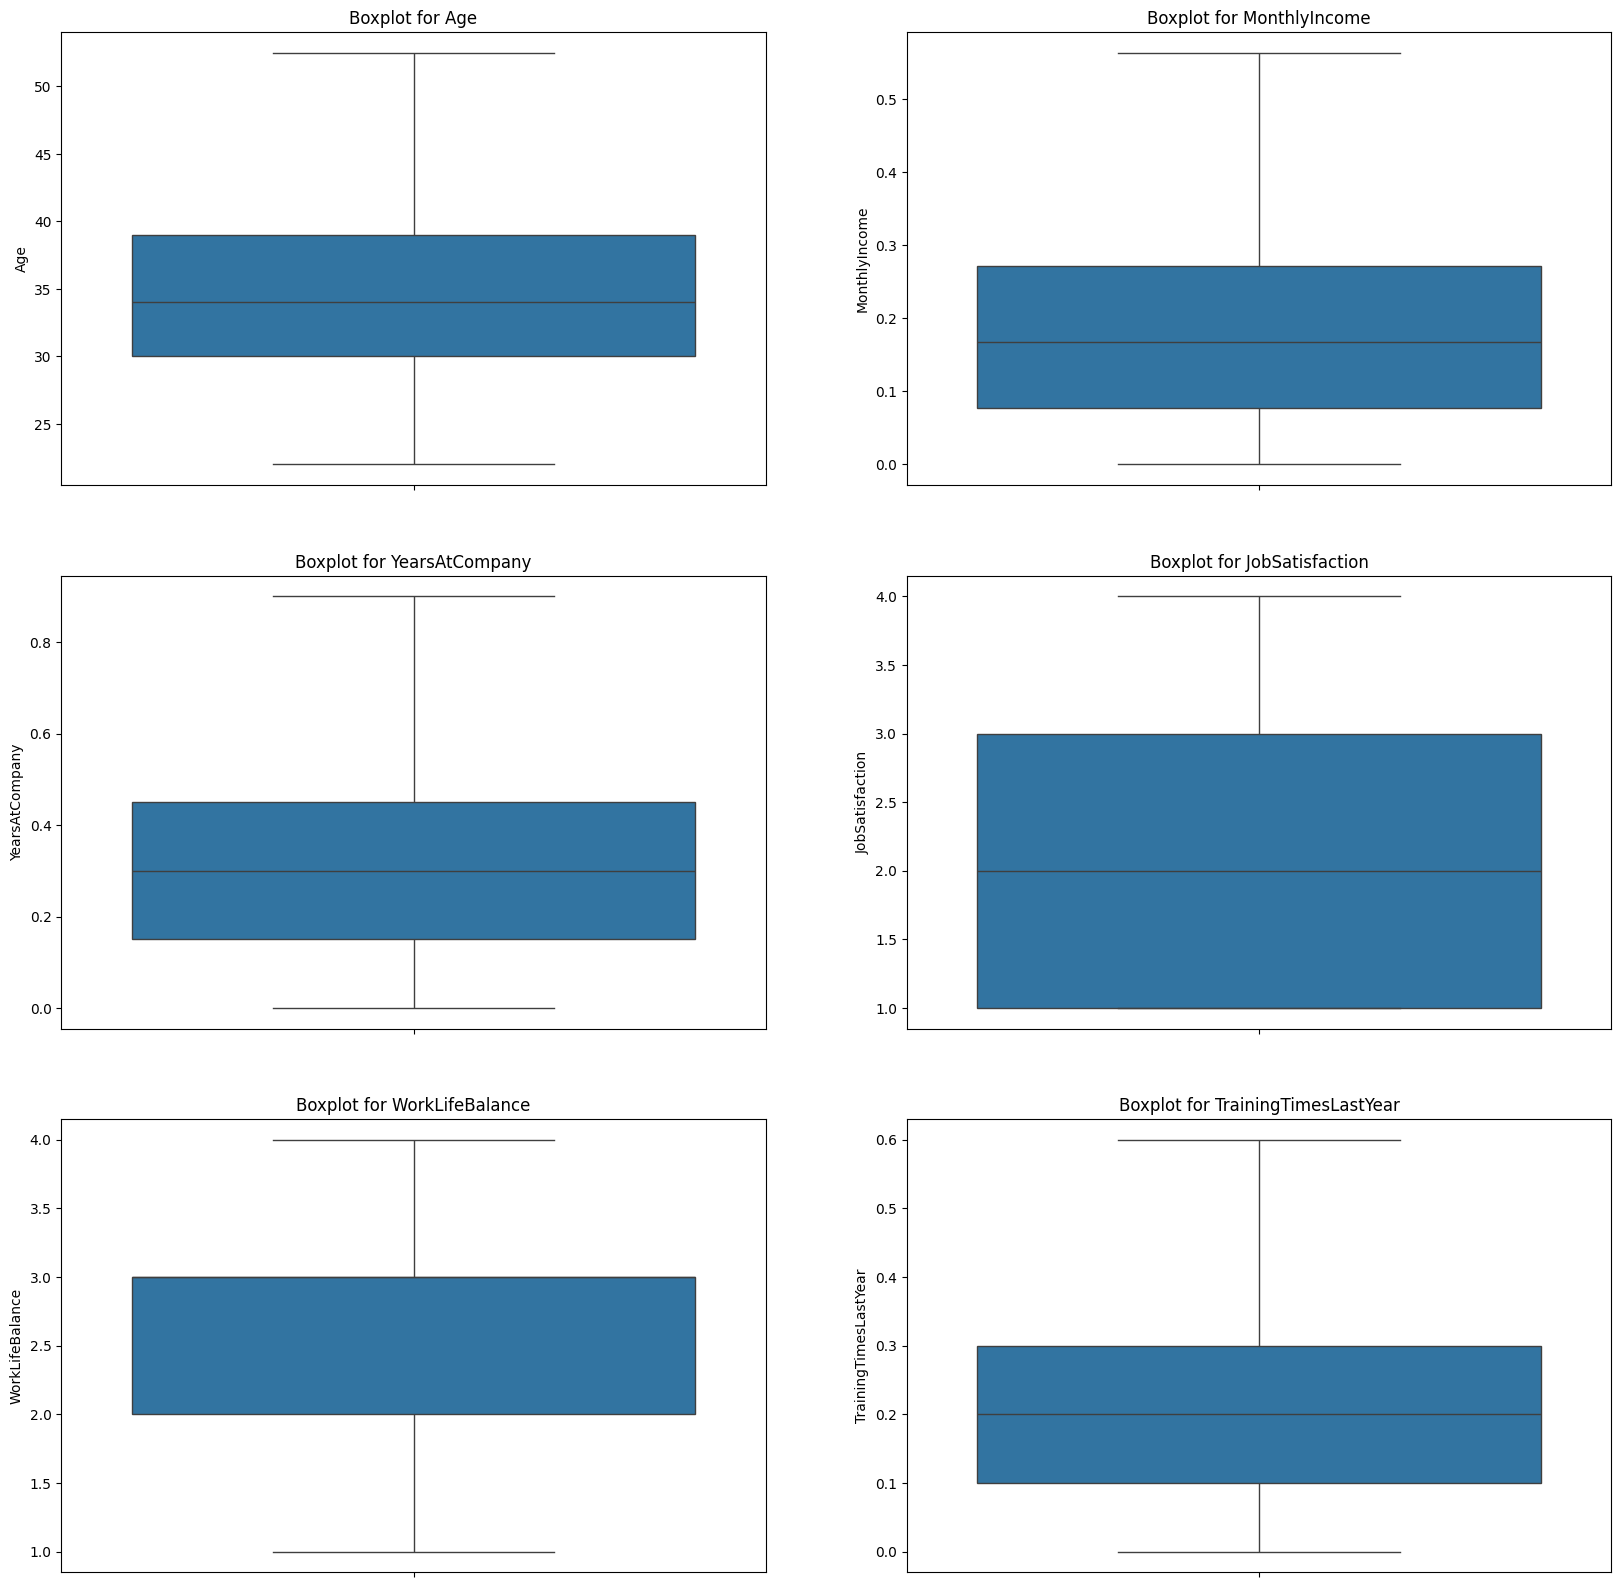

In [133]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(20, 20))
ax=ax.flatten()
for idx, col in enumerate(numerical_columns):
    sns.boxplot(data[col], ax=ax[idx])
    ax[idx].set_title(f"Boxplot for {col}")
plt.show()

### Encode Categorical Variables
Convert categorical variables like `Gender`, `Department`, and `OverTime` into numeric formats.

In [134]:
data.head()

,Age,Gender,Department,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Attrition
0,38.0,Male,HR,0.000000,0.40,No,2.0,3,0.5,No
1,33.0,Male,HR,0.075385,0.25,No,2.0,2,0.3,No
2,40.0,Female,Sales,0.136375,0.70,No,1.0,2,0.5,No
3,47.0,Male,HR,0.174409,0.60,No,3.0,3,0.2,No
4,33.0,Female,IT,0.153290,0.20,No,1.0,3,0.1,Yes


In [135]:
from sklearn.preprocessing import LabelEncoder

In [136]:
# Label encoding for binary categories
encoder = LabelEncoder()


Two step approach:
    1. fit
    2. Transform

In [137]:
data["Gender"].value_counts()

Gender
Female    4036
Male      3956
Name: count, dtype: int64

In [138]:
encoder.fit(data["Gender"]) # fits both category into the encoder

LabelEncoder()

In [139]:
encoder.transform(data["Gender"]) # transforms the categories into numeric(binary)

array([1, 1, 0, ..., 0, 1, 0])

In [140]:
# one line approach
data['Gender'] = encoder.fit_transform(data['Gender'])  
data['OverTime'] = encoder.fit_transform(data['OverTime'])
data['Attrition'] = encoder.fit_transform(data['Attrition'])

In [141]:
data.head()

,Age,Gender,Department,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Attrition
0,38.0,1,HR,0.000000,0.40,0,2.0,3,0.5,0
1,33.0,1,HR,0.075385,0.25,0,2.0,2,0.3,0
2,40.0,0,Sales,0.136375,0.70,0,1.0,2,0.5,0
3,47.0,1,HR,0.174409,0.60,0,3.0,3,0.2,0
4,33.0,0,IT,0.153290,0.20,0,1.0,3,0.1,1


In [142]:
print(data.columns.tolist())

['Age', 'Gender', 'Department', 'MonthlyIncome', 'YearsAtCompany', 'OverTime', 'JobSatisfaction', 'WorkLifeBalance', 'TrainingTimesLastYear', 'Attrition']


In [143]:
# One-hot encoding for multi-class categorical variables
data = pd.get_dummies(data, columns=["Department"], dtype=int)

data.head()

,Age,Gender,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Attrition,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales
0,38.0,1,0.000000,0.40,0,2.0,3,0.5,0,0,1,0,0,0
1,33.0,1,0.075385,0.25,0,2.0,2,0.3,0,0,1,0,0,0
2,40.0,0,0.136375,0.70,0,1.0,2,0.5,0,0,0,0,0,1
3,47.0,1,0.174409,0.60,0,3.0,3,0.2,0,0,1,0,0,0
4,33.0,0,0.153290,0.20,0,1.0,3,0.1,1,0,0,1,0,0


In [144]:
print(data.columns.tolist())

['Age', 'Gender', 'MonthlyIncome', 'YearsAtCompany', 'OverTime', 'JobSatisfaction', 'WorkLifeBalance', 'TrainingTimesLastYear', 'Attrition', 'Department_Finance', 'Department_HR', 'Department_IT', 'Department_Operations', 'Department_Sales']


### Scale Numerical Features
Scale numerical columns to bring them to a similar range, which can improve model performance.

In [145]:
num_cols_to_scale = ['Age', 'MonthlyIncome', 'YearsAtCompany', 'TrainingTimesLastYear']

- StandardScaler: Slightly skewed or normal distribution
- MinMax: Uniform Distribtion
- Robust Scaler: Heavily skewed distribution

In [146]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler # our cols are slightly skewed (Check Hist Above)

In [147]:
# Initialize the scalar
scaler = StandardScaler()

In [148]:
data[num_cols_to_scale] = scaler.fit_transform(data[num_cols_to_scale])

In [149]:
data.head()

,Age,Gender,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Attrition,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales
0,0.479168,1,-1.301722,0.503833,0,2.0,3,1.900458,0,0,1,0,0,0
1,-0.221194,1,-0.778837,-0.232387,0,2.0,2,0.519124,0,0,1,0,0,0
2,0.759312,0,-0.355796,1.976274,0,1.0,2,1.900458,0,0,0,0,0,1
3,1.739818,1,-0.091983,1.485460,0,3.0,3,-0.171543,0,0,1,0,0,0
4,-0.221194,0,-0.238470,-0.477794,0,1.0,3,-0.862210,1,0,0,1,0,0


In [150]:
# Verify scaling
data[num_cols_to_scale].describe()

,Age,MonthlyIncome,YearsAtCompany,TrainingTimesLastYear
count,7.992000e+03,7.992000e+03,7.992000e+03,7.992000e+03
mean,1.013537e-16,-1.049100e-16,2.471608e-16,-6.579099e-17
std,1.000063e+00,1.000063e+00,1.000063e+00,1.000063e+00
min,-1.761989e+00,-1.301722e+00,-1.459421e+00,-1.552877e+00
25%,-6.414110e-01,-7.683502e-01,-7.232007e-01,-8.622104e-01
50%,-8.112171e-02,-1.424711e-01,1.301958e-02,-1.715433e-01
75%,6.192399e-01,5.819226e-01,7.492399e-01,5.191238e-01
max,2.510216e+00,2.607332e+00,2.957901e+00,2.591125e+00


### Check Class Distribution
Assess the balance of the target variable `(Attrition)` to determine if we need to handle class imbalance.

Fix more dominnant class

In [151]:
# Check class distribution
data['Attrition'].value_counts()

Attrition
0    5957
1    2035
Name: count, dtype: int64

In [152]:
data['Attrition'].value_counts(normalize=True)*100

Attrition
0    74.537037
1    25.462963
Name: proportion, dtype: float64

<Axes: xlabel='Attrition', ylabel='count'>

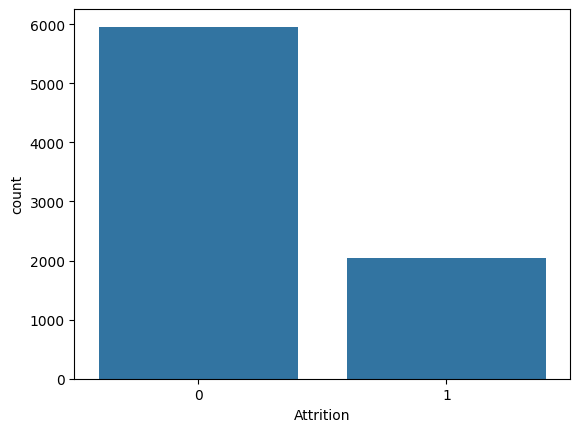

In [153]:
sns.countplot(x=data['Attrition']) #  class zero is far more dominate. 75 - 25. This is a class imbalance

### Handling Class Imbalance
##### Techniques to Address Class Imbalance
- Resampling:
  - Oversampling the minority class using techniques like SMOTE (Synthetic Minority Oversampling Technique).
  - Undersampling the majority class to balance proportions.
  - Oversampling is the better option as undersampling can reduce the data
- Class Weights:
    - Add weights to the classes in the loss function during model training to penalize misclassifications of the minority class.
- Evaluation Metrics:
    - Use metrics like precision, recall, F1-score, or ROC-AUC instead of just accuracy.


#### Oversampling with SMOTE

In [154]:
from imblearn.over_sampling import SMOTE

In [155]:
# Separate features and target
X = data.drop('Attrition', axis=1)
y = data['Attrition']

In [156]:
X.head()

,Age,Gender,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales
0,0.479168,1,-1.301722,0.503833,0,2.0,3,1.900458,0,1,0,0,0
1,-0.221194,1,-0.778837,-0.232387,0,2.0,2,0.519124,0,1,0,0,0
2,0.759312,0,-0.355796,1.976274,0,1.0,2,1.900458,0,0,0,0,1
3,1.739818,1,-0.091983,1.485460,0,3.0,3,-0.171543,0,1,0,0,0
4,-0.221194,0,-0.238470,-0.477794,0,1.0,3,-0.862210,0,0,1,0,0


In [157]:
y.head()

0    0
1    0
2    0
3    0
4    1
Name: Attrition, dtype: int32

In [158]:
# Apply SMOTE to oversample the minority class
smote = SMOTE(random_state=42)

In [159]:
X_resampled, y_resampled = smote.fit_resample(X, y)

In [160]:
data.isnull().sum()

Age                      0
Gender                   0
MonthlyIncome            0
YearsAtCompany           0
OverTime                 0
JobSatisfaction          0
WorkLifeBalance          0
TrainingTimesLastYear    0
Attrition                0
Department_Finance       0
Department_HR            0
Department_IT            0
Department_Operations    0
Department_Sales         0
dtype: int64

In [161]:
y_resampled.value_counts()

Attrition
0    5957
1    5957
Name: count, dtype: int64

In [162]:
y_resampled.value_counts(normalize=True)*100

Attrition
0    50.0
1    50.0
Name: proportion, dtype: float64

<Axes: xlabel='Attrition', ylabel='count'>

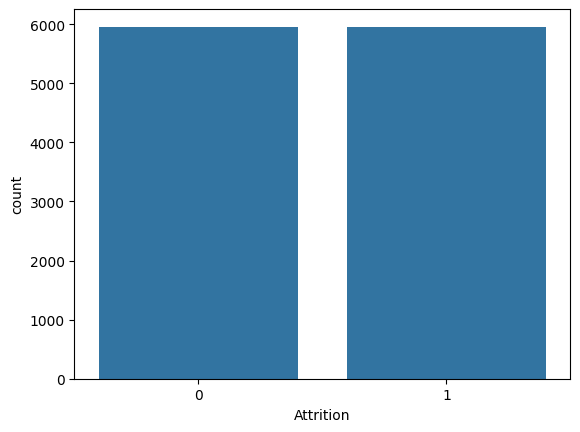

In [163]:
sns.countplot(x=y_resampled)

In [164]:
resampled_data = pd.DataFrame(X_resampled, columns=X.columns)

In [165]:
resampled_data.head()

,Age,Gender,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales
0,0.479168,1,-1.301722,0.503833,0,2.0,3,1.900458,0,1,0,0,0
1,-0.221194,1,-0.778837,-0.232387,0,2.0,2,0.519124,0,1,0,0,0
2,0.759312,0,-0.355796,1.976274,0,1.0,2,1.900458,0,0,0,0,1
3,1.739818,1,-0.091983,1.485460,0,3.0,3,-0.171543,0,1,0,0,0
4,-0.221194,0,-0.238470,-0.477794,0,1.0,3,-0.862210,0,0,1,0,0


In [166]:
resampled_data["Attrition"] = y_resampled

In [167]:
resampled_data.head()

,Age,Gender,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales,Attrition
0,0.479168,1,-1.301722,0.503833,0,2.0,3,1.900458,0,1,0,0,0,0
1,-0.221194,1,-0.778837,-0.232387,0,2.0,2,0.519124,0,1,0,0,0,0
2,0.759312,0,-0.355796,1.976274,0,1.0,2,1.900458,0,0,0,0,1,0
3,1.739818,1,-0.091983,1.485460,0,3.0,3,-0.171543,0,1,0,0,0,0
4,-0.221194,0,-0.238470,-0.477794,0,1.0,3,-0.862210,0,0,1,0,0,1


### Final Dataset Ready
At this stage, the dataset is clean and prepared for the next step in the workflow.

In [168]:
# Save the cleaned dataset for future use
resampled_data.to_csv('files/WMDI-files/cleaned_employee_attrition_balanced.csv', index=False)

In [169]:
df = pd.read_csv("files/WMDI-files/cleaned_employee_attrition_balanced.csv")

In [170]:
df["Attrition"].value_counts()

Attrition
0    5957
1    5957
Name: count, dtype: int64

### Data Splitting
We’ll split the cleaned dataset into training and testing sets, ensuring the target variable’s distribution is representative in both.

In [171]:
from sklearn.model_selection import train_test_split

In [172]:
# Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_resampled, y_resampled, test_size=0.2, random_state=42, stratify=y_resampled  # Stratify to maintain class proportions
)

In [173]:
print(f"Training data size {len(X_train)}")
print(f"Training data size {len(X_test)}")

Training data size 9531
Training data size 2383


In [174]:
y_train.value_counts(normalize=True) * 100

Attrition
1    50.005246
0    49.994754
Name: proportion, dtype: float64

In [175]:
y_test.value_counts(normalize=True) * 100

Attrition
0    50.020982
1    49.979018
Name: proportion, dtype: float64

### Model Selection
We’ll train multiple classification models to find the best one for predicting attrition. Start with a baseline and expand to more advanced models.

### 1. Train a Baseline Model (Logistic Regression)  
##### Logistics Regression is for classification(Binary 0 and 1) (We going with this since our target is in binary)
##### Linear Regression is for continous data

In [176]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [177]:
# Model Initialization
model = LogisticRegression(random_state=42)

In [178]:
# model = LogisticRegression(class_weight='balanced', random_state=42)
# Model Training
model.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [179]:
# Predict on the test set
y_pred = model.predict(X_test)

In [180]:
y_pred

array([1, 1, 1, ..., 0, 1, 1])

In [181]:
print(y_test[:5])

155      0
5239     0
11616    1
450      0
6944     0
Name: Attrition, dtype: int32


In [182]:
y_pred[:5]

array([1, 1, 1, 0, 0])

In [183]:
report = classification_report(y_test, y_pred)
matrix = confusion_matrix(y_test, y_pred)

In [184]:
# Evaluate performance
print("Logistic Regression Classification Report:\n")
print(report)

Logistic Regression Classification Report:

              precision    recall  f1-score   support

           0       0.55      0.61      0.58      1192
           1       0.57      0.51      0.53      1191

    accuracy                           0.56      2383
   macro avg       0.56      0.56      0.56      2383
weighted avg       0.56      0.56      0.56      2383



In [185]:
y_test.value_counts()

Attrition
0    1192
1    1191
Name: count, dtype: int64

In [186]:
len(y_test)

2383

### 2. Train Advanced Models (Random Forest)

In [187]:
from sklearn.ensemble import RandomForestClassifier

In [188]:
# Model Initialization

# class_weight='balanced' automatically gives higher weight to the minority class.
# Example: Imagine a cancer dataset with 9,000 cancer-negative patients (class 0)
# and 1,000 cancer-positive patients (class 1).
# Without balancing, the model may favour class 0 because it has more examples.
# With 'balanced', mistakes on class 1 receive higher weight, helping the model
# pay more attention to cancer-positive cases during training.

rf_model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_estimators=100
)


# ALTERNATIVE: Manually assign class weights

# class_weight={0:1, 1:3} means:
# Class 0 (Cancer Negative): Weight = 1
# Class 1 (Cancer Positive): Weight = 3
#
# This makes each mistake on a cancer-positive patient count 3 times as much
# as an equally weighted mistake on a cancer-negative patient during training.
#
# The goal is to discourage the model from ignoring cancer-positive patients
# simply because they are fewer in the dataset.
#
# IMPORTANT: Higher weights do not guarantee better predictions.
# Evaluate recall, precision and the confusion matrix to check performance.

# rf_model = RandomForestClassifier(
#     class_weight={0:1, 1:3},
#     random_state=42,
#     n_estimators=100
# )

## We will continue with class_weight='balance' since we've already used SMOTE

In [189]:
# Model Train
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [190]:
# Predict on the test set
y_pred_rf_model = rf_model.predict(X_test)
# Evaluate performance
print("Random Forest Classification Report:\n")
print(classification_report(y_test, y_pred_rf_model))

Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.87      0.83      1192
           1       0.86      0.77      0.81      1191

    accuracy                           0.82      2383
   macro avg       0.83      0.82      0.82      2383
weighted avg       0.83      0.82      0.82      2383



### 3. Trying multiple classification models

In [191]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [192]:
from xgboost import XGBClassifier

In [193]:
# Define the models
# class_weights={0:1, 1:3}
class_weights='balanced'
models = {
    'Logistic Regression': LogisticRegression(random_state=42, class_weight=class_weights),
    'Random Forest': RandomForestClassifier(random_state=42, class_weight=class_weights),
    'SVC': SVC(random_state=42, class_weight=class_weights),
    'k-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight=class_weights),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='mlogloss')
}

Training Logistic Regression...
Logistic Regression Classification Report: 
              precision    recall  f1-score   support

           0       0.55      0.61      0.58      1192
           1       0.57      0.50      0.53      1191

    accuracy                           0.56      2383
   macro avg       0.56      0.56      0.56      2383
weighted avg       0.56      0.56      0.56      2383



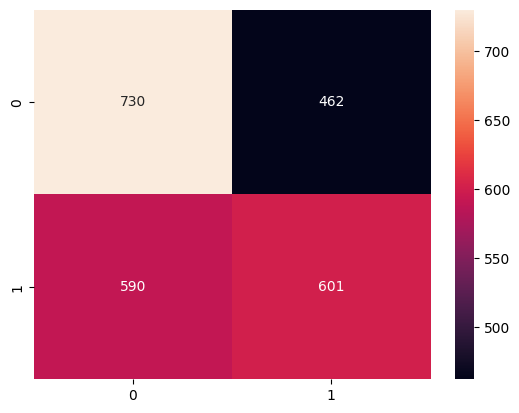

Training Random Forest...
Random Forest Classification Report: 
              precision    recall  f1-score   support

           0       0.79      0.87      0.83      1192
           1       0.86      0.77      0.81      1191

    accuracy                           0.82      2383
   macro avg       0.83      0.82      0.82      2383
weighted avg       0.83      0.82      0.82      2383



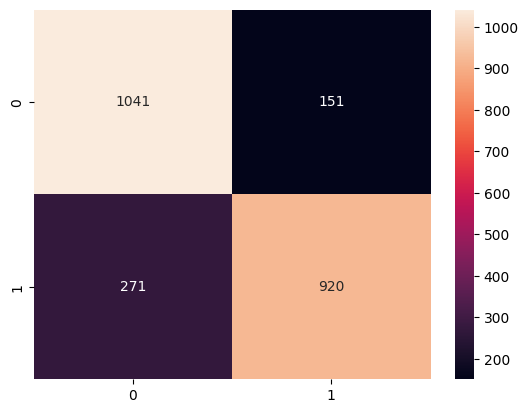

Training SVC...
SVC Classification Report: 
              precision    recall  f1-score   support

           0       0.61      0.52      0.56      1192
           1       0.58      0.66      0.62      1191

    accuracy                           0.59      2383
   macro avg       0.59      0.59      0.59      2383
weighted avg       0.59      0.59      0.59      2383



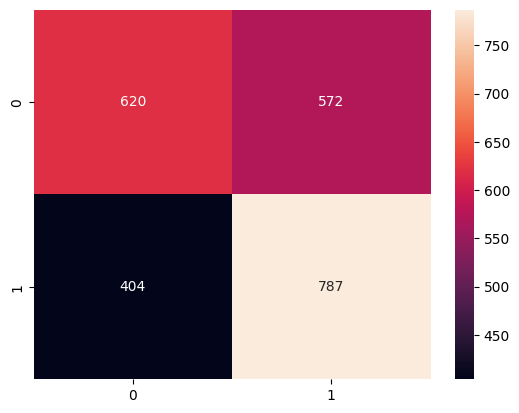

Training k-Nearest Neighbors...
k-Nearest Neighbors Classification Report: 
              precision    recall  f1-score   support

           0       0.78      0.53      0.63      1192
           1       0.65      0.85      0.73      1191

    accuracy                           0.69      2383
   macro avg       0.71      0.69      0.68      2383
weighted avg       0.71      0.69      0.68      2383



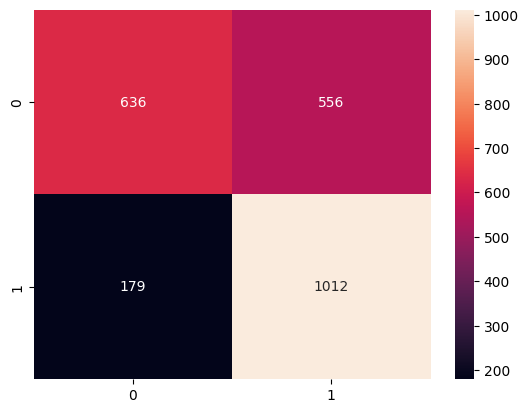

Training Decision Tree...
Decision Tree Classification Report: 
              precision    recall  f1-score   support

           0       0.72      0.67      0.69      1192
           1       0.69      0.74      0.71      1191

    accuracy                           0.70      2383
   macro avg       0.70      0.70      0.70      2383
weighted avg       0.70      0.70      0.70      2383



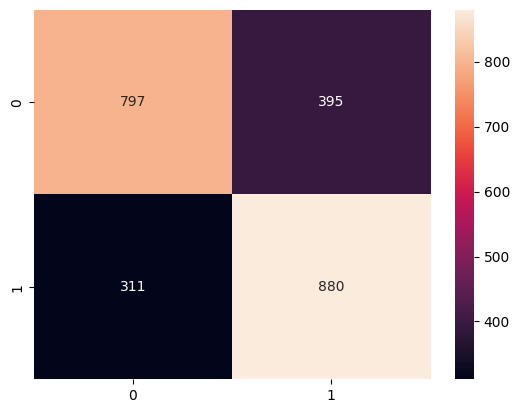

Training Gradient Boosting...
Gradient Boosting Classification Report: 
              precision    recall  f1-score   support

           0       0.71      0.97      0.82      1192
           1       0.95      0.60      0.74      1191

    accuracy                           0.79      2383
   macro avg       0.83      0.79      0.78      2383
weighted avg       0.83      0.79      0.78      2383



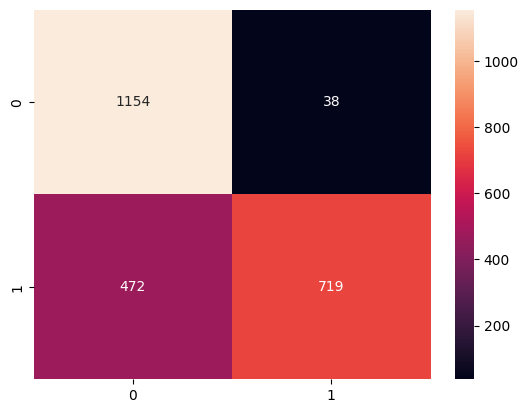

Training AdaBoost...


c:\Users\LENOVO\OneDrive\Desktop\DS_course\Course Materials\Python\python-data-science-lab\.venv-pycaret\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


AdaBoost Classification Report: 
              precision    recall  f1-score   support

           0       0.62      0.68      0.65      1192
           1       0.65      0.59      0.62      1191

    accuracy                           0.63      2383
   macro avg       0.63      0.63      0.63      2383
weighted avg       0.63      0.63      0.63      2383



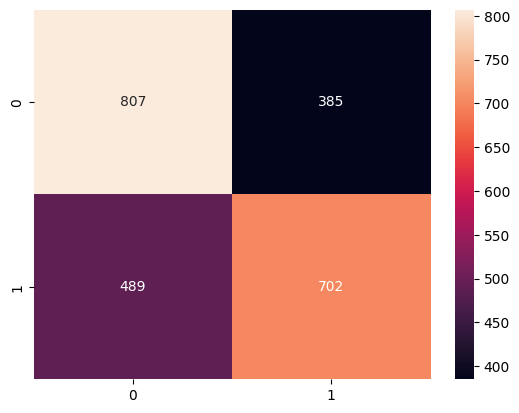

Training XGBoost...
XGBoost Classification Report: 
              precision    recall  f1-score   support

           0       0.74      0.88      0.80      1192
           1       0.85      0.69      0.76      1191

    accuracy                           0.79      2383
   macro avg       0.80      0.79      0.78      2383
weighted avg       0.80      0.79      0.78      2383



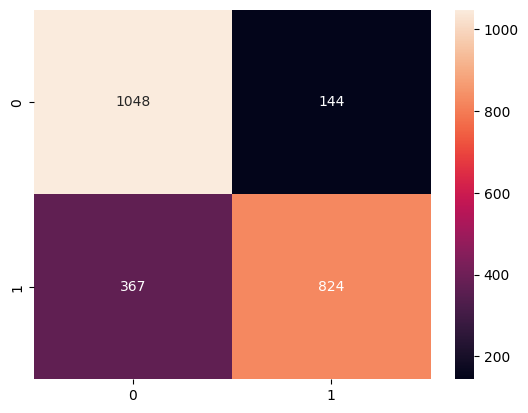

In [194]:
from sklearn.metrics import accuracy_score
results = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")
    # Train the model
    model.fit(X_train, y_train)
    
    # Make predictions
    y_pred = model.predict(X_test)
    
    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred)
    matrix = confusion_matrix(y_test, y_pred)
    
    # Store results
    results[model_name] = {
        'accuracy': accuracy,
        'classification_report': report,
        'confusion_matrix': matrix
    }
    # print(f"{model_name} Accuracy: {accuracy:.4f}")
    print(f"{model_name} Classification Report: \n{report}")

    sns.heatmap(matrix, annot=True, fmt="g") # g for general annotation of numbers in each numbers
    plt.show()

### 4. Hyperparameter Tuning
We’ll use grid search to optimize hyperparameters for the Random Forest model.

In [195]:
from sklearn.model_selection import GridSearchCV

In [196]:
# Define parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [197]:
grid_search = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid, cv=5, scoring='f1', n_jobs=-1
)

In [198]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=RandomForestClassifier(class_weight='balanced',
                                              random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]},
             scoring='f1')

In [199]:
# Best parameters
print("Best Hyperparameters:", grid_search.best_params_)

Best Hyperparameters: {'max_depth': 30, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [200]:
# Train best model
best_rf = grid_search.best_estimator_

In [201]:
# Predict on the test set
y_pred_best_rf = best_rf.predict(X_test)

In [202]:
# Evaluate performance
print("Fine Tuned Random Forest Classification Report:\n")
report = classification_report(y_test, y_pred_best_rf)
print(report)

Fine Tuned Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.87      0.83      1192
           1       0.86      0.78      0.82      1191

    accuracy                           0.83      2383
   macro avg       0.83      0.83      0.83      2383
weighted avg       0.83      0.83      0.83      2383



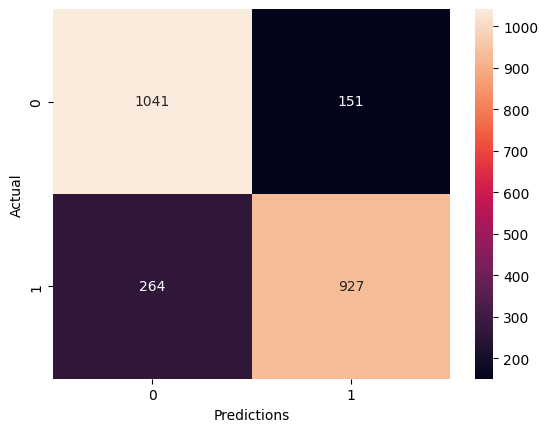

In [203]:
matrix = confusion_matrix(y_test, y_pred_best_rf)
sns.heatmap(matrix, annot=True, fmt="g")
plt.xlabel("Predictions")
plt.ylabel("Actual")
plt.show()

#### ROC Curve and AUC Score
ROC-AUC to evaluate the model's ability to distinguish between classes.

In [204]:
from sklearn.metrics import roc_curve, roc_auc_score

In [205]:
# Compute probabilities for ROC
y_probs = best_rf.predict_proba(X_test)[:, 1]  # Probabilities for the positive class

In [206]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc_score = roc_auc_score(y_test, y_probs)

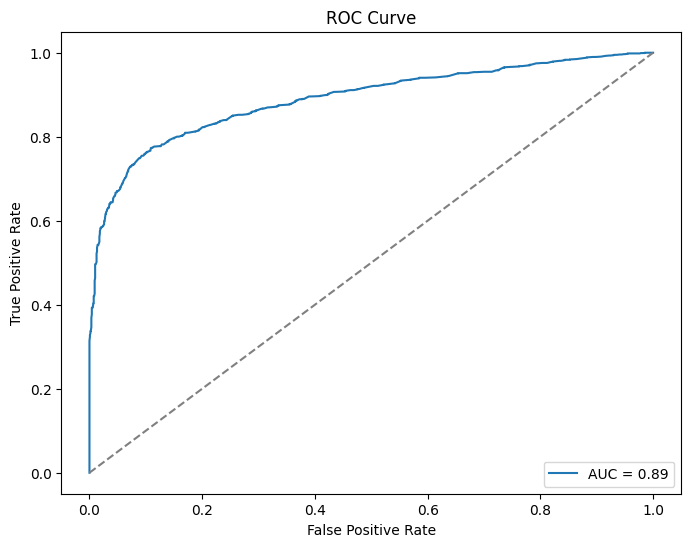

In [207]:
# Plot ROC curve
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

### The following PyCaret Method only works on Python 3.11.17

### 6. Using AutoML to select best model

#### Using PyCaret
PyCaret is a low-code library for automating machine learning workflows.

In [208]:
import sys
import pycaret

print("Python:", sys.version)
print("PyCaret:", pycaret.__version__)

import six

print("six version:", six.__version__)

Python: 3.11.17 (main, Oct  3 2026, 01:03:09) [MSC v.1944 64 bit (AMD64)]
PyCaret: 3.3.2
six version: 1.17.0


In [212]:
from pycaret.classification import *

In [213]:
# Combine features and target into one DataFrame
# df = pd.concat([X, y], axis=1)
df = pd.concat([X_resampled, y_resampled], axis=1)

In [214]:
df.head()

,Age,Gender,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales,Attrition
0,0.479168,1,-1.301722,0.503833,0,2.0,3,1.900458,0,1,0,0,0,0
1,-0.221194,1,-0.778837,-0.232387,0,2.0,2,0.519124,0,1,0,0,0,0
2,0.759312,0,-0.355796,1.976274,0,1.0,2,1.900458,0,0,0,0,1,0
3,1.739818,1,-0.091983,1.485460,0,3.0,3,-0.171543,0,1,0,0,0,0
4,-0.221194,0,-0.238470,-0.477794,0,1.0,3,-0.862210,0,0,1,0,0,1


In [215]:
# Initialize PyCaret
clf_setup = setup(
    data=df, 
    target='Attrition', 
    normalize=True,
    session_id=42, # random_state=42 in the other models
    # use_gpu=True,
)

,Description,Value
0,Session id,42
1,Target,Attrition
2,Target type,Binary
3,Original data shape,"(11914, 14)"
4,Transformed data shape,"(11914, 14)"
5,Transformed train set shape,"(8339, 14)"
6,Transformed test set shape,"(3575, 14)"
7,Numeric features,13
8,Preprocess,True
9,Imputation type,simple


In [216]:
# Compare models and select the best one
best_model = compare_models(cross_validation=False, sort="f1")

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.8103,0.8784,0.7722,0.8359,0.8028,0.6207,0.6225,5.1000
et,Extra Trees Classifier,0.7983,0.8727,0.7974,0.7988,0.7981,0.5966,0.5966,3.3100
xgboost,Extreme Gradient Boosting,0.7922,0.8380,0.6883,0.8686,0.7680,0.5843,0.5973,0.8000
gbc,Gradient Boosting Classifier,0.7989,0.8250,0.6223,0.9619,0.7557,0.5977,0.6389,10.1900
knn,K Neighbors Classifier,0.6680,0.7329,0.7952,0.6338,0.7054,0.3360,0.3474,0.1000
dt,Decision Tree Classifier,0.6999,0.6999,0.7163,0.6934,0.7047,0.3997,0.3999,0.2400
dummy,Dummy Classifier,0.4999,0.5000,1.0000,0.4999,0.6665,0.0000,0.0000,0.0500
ada,Ada Boost Classifier,0.6618,0.7307,0.6167,0.6777,0.6458,0.3236,0.3249,1.0400
nb,Naive Bayes,0.5538,0.5758,0.5820,0.5508,0.5660,0.1077,0.1079,0.0500
svm,SVM - Linear Kernel,0.5396,0.5396,0.5339,0.5399,0.5369,0.0792,0.0792,0.2100


In [ ]:
# Display the best model
print(best_model) # Parameters that got the best out of the best model

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=100, n_jobs=-1,
                       oob_score=False, random_state=42, verbose=0,
                       warm_start=False)


In [219]:
# Fine-tune the best model
tuned_model = tune_model(best_model, optimize="f1", fold=5)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.7284,0.8014,0.7146,0.7349,0.7246,0.4568,0.4570
1,0.7104,0.7810,0.6835,0.7224,0.7024,0.4209,0.4215
2,0.7128,0.7792,0.7098,0.7141,0.7120,0.4257,0.4257
3,0.7404,0.8062,0.6859,0.7699,0.7254,0.4808,0.4837
4,0.7145,0.7819,0.7410,0.7039,0.7220,0.4289,0.4295
Mean,0.7213,0.7900,0.7070,0.7290,0.7173,0.4426,0.4435
Std,0.0114,0.0115,0.0211,0.0228,0.0089,0.0228,0.0237


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


#### Original model already works better than the tuned model. But we went further incase we are happy with the runed results

In [220]:
# Finalize the model
final_model = finalize_model(tuned_model)

In [221]:
# Predict on the test set
predictions = predict_model(final_model, data=X_test)

In [222]:
predictions

,Age,Gender,MonthlyIncome,YearsAtCompany,OverTime,JobSatisfaction,WorkLifeBalance,TrainingTimesLastYear,Department_Finance,Department_HR,Department_IT,Department_Operations,Department_Sales,prediction_label,prediction_score
155,-0.781483,0,-0.311053,-0.477794,0,3.0,3,0.519124,0,0,0,0,1,0,0.86
5239,1.039457,0,0.688116,0.749240,0,4.0,2,-0.171543,0,0,0,1,0,0,0.78
11616,0.015012,0,-1.243452,0.946525,0,1.0,1,-0.862210,0,1,0,0,0,1,0.87
450,-0.081122,0,2.379747,0.013020,0,1.0,4,0.519124,0,0,1,0,0,0,0.82
6944,-1.621917,0,-0.680664,-1.459421,1,1.0,3,0.519124,0,1,0,0,0,0,0.73
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3352,0.058951,1,-1.301721,-0.232387,0,1.0,3,-0.862210,0,0,0,1,0,0,0.90
10220,0.321504,0,-1.301721,0.728693,0,1.0,3,0.490211,0,1,0,0,0,1,0.99
5504,-0.221194,1,0.698072,-0.232387,0,3.0,3,-0.171543,0,1,0,0,0,0,0.86
7354,1.179529,0,0.726341,1.485460,0,4.0,2,-0.862210,0,0,0,1,0,1,0.84


#### Saving the model

In [223]:
save_model(final_model, 'final_model_attrition_prediction')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Age', 'Gender', 'MonthlyIncome',
                                              'YearsAtCompany', 'OverTime',
                                              'JobSatisfaction',
                                              'WorkLifeBalance',
                                              'TrainingTimesLastYear',
                                              'Department_Finance',
                                              'Department_HR', 'Department_IT',
                                              'Department_Operations',
                                              'Department_Sales'],
                                     transformer=SimpleImputer(a...
                  RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                         class_weight=None, criterion='gini',
         

#### Loading the model

In [224]:
loaded_model = load_model('final_model_attrition_prediction')

Transformation Pipeline and Model Successfully Loaded


In [226]:
loaded_model

Pipeline(memory=FastMemory(location=C:\Users\LENOVO\AppData\Local\Temp\joblib),
         steps=[('numerical_imputer',
                 TransformerWrapper(exclude=None,
                                    include=['Age', 'Gender', 'MonthlyIncome',
                                             'YearsAtCompany', 'OverTime',
                                             'JobSatisfaction',
                                             'WorkLifeBalance',
                                             'TrainingTimesLastYear',
                                             'Department_Finance',
                                             'Department_HR', 'Department_IT',
                                             'Department_Operations',
                                             'Depar...
                 RandomForestClassifier(bootstrap=True, ccp_alpha=0.0,
                                        class_weight=None, criterion='gini',
                                        max_depth=None, max_features='sqrt',
                                        max_leaf_nodes=None, max_samples=None,
                                        min_impurity_decrease=0.0,
                                        min_samples_leaf=1, min_samples_split=2,
                                        min_weight_fraction_leaf=0.0,
                                        monotonic_cst=None, n_estimators=100,
                                        n_jobs=-1, oob_score=False,
                                        random_state=42, verbose=0,
                                        warm_start=False))],
         verbose=False)

In [228]:
#loaded_model.predict() # going forward